In [4]:
import tensorflow as tf
from tensorflow.keras import datasets , layers , models 

import matplotlib.pyplot as plt
import numpy as np

In [5]:
(X_train,y_train),(X_test,y_test) = datasets.cifar10.load_data()

In [6]:
X_train.shape

(50000, 32, 32, 3)

In [7]:
X_test.shape

(10000, 32, 32, 3)

In [8]:
X_train[0]

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]

In [20]:
y_train[:5]

array([[6],
       [9],
       [9],
       [4],
       [1]], dtype=uint8)

In [21]:
y_train.shape

(50000, 1)

In [22]:
y_train = y_train.reshape(-1,)
y_train[:5]

array([6, 9, 9, 4, 1], dtype=uint8)

In [17]:
classes = ["airplane" , "automobile" , "bird" , "cat" , "deer" , "dog" , "frog" , "horse" , "ship" , "truck"]

In [23]:
classes[9]

'truck'

In [24]:
def plot_sample(X,y,index):
    
    plt.figure(figsize=(2,2))
    plt.imshow(X[index])
    plt.xlabel(classes[y[index]])

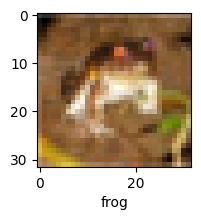

In [25]:
plot_sample(X_train,y_train ,0)

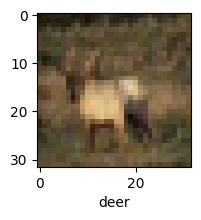

In [28]:
plot_sample(X_train,y_train ,3)

In [30]:
X_train[0]/255

array([[[0.23137255, 0.24313725, 0.24705882],
        [0.16862745, 0.18039216, 0.17647059],
        [0.19607843, 0.18823529, 0.16862745],
        ...,
        [0.61960784, 0.51764706, 0.42352941],
        [0.59607843, 0.49019608, 0.4       ],
        [0.58039216, 0.48627451, 0.40392157]],

       [[0.0627451 , 0.07843137, 0.07843137],
        [0.        , 0.        , 0.        ],
        [0.07058824, 0.03137255, 0.        ],
        ...,
        [0.48235294, 0.34509804, 0.21568627],
        [0.46666667, 0.3254902 , 0.19607843],
        [0.47843137, 0.34117647, 0.22352941]],

       [[0.09803922, 0.09411765, 0.08235294],
        [0.0627451 , 0.02745098, 0.        ],
        [0.19215686, 0.10588235, 0.03137255],
        ...,
        [0.4627451 , 0.32941176, 0.19607843],
        [0.47058824, 0.32941176, 0.19607843],
        [0.42745098, 0.28627451, 0.16470588]],

       ...,

       [[0.81568627, 0.66666667, 0.37647059],
        [0.78823529, 0.6       , 0.13333333],
        [0.77647059, 0

In [31]:
X_train = X_train / 255
X_test = X_test / 255

In [33]:
ann = models.Sequential([
        layers.Flatten(input_shape =(32,32,3)),
        layers.Dense(units=3000, activation='relu'),
        layers.Dense(units=1000, activation='relu'),
        layers.Dense(units=10, activation='softmax')
    
    ])
ann.compile(optimizer="SGD",
            loss = 'sparse_categorical_crossentropy',
            metrics =['accuracy'])
ann.fit(X_train,y_train,epochs=5)

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 51s 31ms/step - accuracy: 0.3508 - loss: 1.8140
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 50s 32ms/step - accuracy: 0.4289 - loss: 1.6228
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 49s 31ms/step - accuracy: 0.4564 - loss: 1.5435
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 49s 31ms/step - accuracy: 0.4781 - loss: 1.4808
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 86s 34ms/step - accuracy: 0.4946 - loss: 1.4324


In [35]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

y_pred = ann.predict(X_test)
y_pred_classes = [np.argmax(element) for element in y_pred]

print("Classification report : \n",classification_report(y_test,y_pred_classes))

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step
Classification report : 
               precision    recall  f1-score   support

           0       0.55      0.57      0.56      1000
           1       0.41      0.82      0.55      1000
           2       0.30      0.49      0.38      1000
           3       0.39      0.18      0.24      1000
           4       0.58      0.15      0.23      1000
           5       0.41      0.38      0.40      1000
           6       0.43      0.68      0.53      1000
           7       0.78      0.34      0.48      1000
           8       0.66      0.56      0.61      1000
           9       0.54      0.43      0.48      1000

    accuracy                           0.46     10000
   macro avg       0.50      0.46      0.44     10000
weighted avg       0.50      0.46      0.44     10000



In [37]:
cnn = models.Sequential([

        # cnn
        layers.Conv2D(filters=32 , kernel_size=(3,3) , activation='relu', input_shape =(32,32,3)),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(filters=64, kernel_size=(3,3) , activation='relu'),
        layers.MaxPooling2D((2,2)),
    
        # dense
        layers.Flatten(),
        layers.Dense(units=64, activation='relu'),
        layers.Dense(units=10, activation='softmax')
    
    ])

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [38]:
cnn.compile(
        loss='sparse_categorical_crossentropy',
        optimizer='adam',
        metrics =['accuracy']
)

In [39]:
cnn.fit(X_train,y_train, epochs=10)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 16ms/step - accuracy: 0.4558 - loss: 1.5061
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.5969 - loss: 1.1469
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.6483 - loss: 1.0140
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 27s 17ms/step - accuracy: 0.6728 - loss: 0.9408
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.6949 - loss: 0.8815
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 24s 15ms/step - accuracy: 0.7119 - loss: 0.8318
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 24s 15ms/step - accuracy: 0.7263 - loss: 0.7875
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.7398 - loss: 0.7544
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.7508 - loss: 0.7125
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.7622 - loss: 0.6831


In [41]:
cnn.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6936 - loss: 0.9140


[0.9140493273735046, 0.6935999989509583]

In [42]:
y_test[:5]

array([[3],
       [8],
       [8],
       [0],
       [6]], dtype=uint8)

In [43]:
y_test.shape

(10000, 1)

In [44]:
y_test =y_test.reshape(-1,)

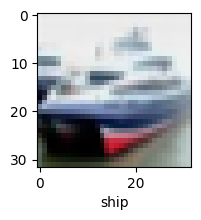

In [45]:
plot_sample(X_test,y_test ,1)

In [46]:
y_pred = cnn.predict(X_test)
y_pred[:5]

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


array([[6.0502702e-04, 2.4338241e-04, 1.6994233e-03, 6.8565875e-01,
        7.5551895e-03, 2.6585761e-01, 1.9876413e-02, 3.2288469e-03,
        1.3718750e-02, 1.5565803e-03],
       [1.1537673e-03, 4.0122550e-02, 1.8361119e-05, 1.6441731e-05,
        1.3318394e-06, 2.5019722e-07, 2.4043372e-08, 1.1415599e-06,
        9.5812321e-01, 5.6284852e-04],
       [9.8225353e-03, 1.8912744e-02, 2.2790905e-03, 2.4649829e-03,
        8.4729248e-04, 1.2782266e-04, 3.4993779e-04, 4.8090070e-03,
        9.4932866e-01, 1.1057990e-02],
       [9.7439188e-01, 4.7083604e-03, 1.3714759e-02, 6.9075980e-04,
        8.2306482e-04, 1.4635634e-05, 4.2704323e-05, 4.1447699e-04,
        5.1346500e-03, 6.4668435e-05],
       [9.2504672e-07, 2.1035219e-05, 3.3962349e-03, 1.1330355e-02,
        7.4965817e-01, 8.5825525e-04, 2.3468801e-01, 1.4129714e-06,
        3.9352479e-05, 6.3103485e-06]], dtype=float32)

In [47]:
np.argmax([2,12,4,5,6,8])

np.int64(1)

In [48]:
np.argmax(y_pred[0])

np.int64(3)

In [49]:
y_classes = [ np.argmax(element) for element in y_pred]
y_classes[:5]

[np.int64(3), np.int64(8), np.int64(8), np.int64(0), np.int64(4)]

In [50]:
y_test[:5]

array([3, 8, 8, 0, 6], dtype=uint8)

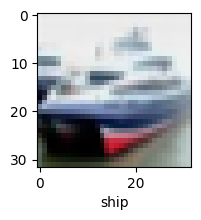

In [52]:
plot_sample(X_test,y_test,1)

In [53]:
classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

In [54]:
classes[y_classes[1]]

'ship'

'truck'

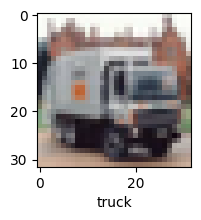

In [57]:
plot_sample(X_test,y_test,11) # actual
classes[y_classes[11]] # predicted

In [58]:
print( "Classification report : \n", classification_report(y_test ,y_classes))

Classification report : 
               precision    recall  f1-score   support

           0       0.76      0.72      0.74      1000
           1       0.82      0.80      0.81      1000
           2       0.61      0.60      0.61      1000
           3       0.54      0.42      0.47      1000
           4       0.63      0.66      0.64      1000
           5       0.54      0.68      0.60      1000
           6       0.77      0.73      0.75      1000
           7       0.68      0.79      0.73      1000
           8       0.81      0.78      0.79      1000
           9       0.79      0.78      0.78      1000

    accuracy                           0.69     10000
   macro avg       0.70      0.69      0.69     10000
weighted avg       0.70      0.69      0.69     10000

